## GLM Poisson - Datos en áreas

In [ ]:
import geopandas as gpd
import pandas as pd

In [ ]:
panel = gpd.read_file("barrios_final.gpkg")

In [62]:
# --- Paso 1: Datos 2018 ---
df18 = panel[panel["year"] == 2018].copy()

print(f"Observaciones: {len(df18)}")
print(df18[["hurto_res", "hurto_per", "incaut_spa", "viviendas", 
            "ndvi", "gradiente", "estrato_moda"]].describe().round(3))

Observaciones: 232
       hurto_res  hurto_per  incaut_spa  viviendas     ndvi  gradiente  \
count    232.000    232.000     232.000    232.000  232.000    232.000   
mean       8.517     92.509      46.121   3367.836    0.348      0.016   
std        6.167    196.444      91.699   1831.166    0.106      0.007   
min        0.000      0.000       0.000    601.000    0.162      0.003   
25%        4.000     18.000       5.000   1978.000    0.267      0.011   
50%        7.000     43.500      16.000   2969.500    0.327      0.015   
75%       11.000    104.000      47.250   4354.000    0.423      0.020   
max       30.000   2630.000     993.000   9414.000    0.712      0.041   

       estrato_moda  
count       232.000  
mean          3.017  
std           1.417  
min           1.000  
25%           2.000  
50%           3.000  
75%           4.000  
max           6.000  


In [69]:
# --- Paso 2: Tasas, transformaciones y offset ---
import numpy as np

# Tasas delictivas por 1000 habitantes
df18["tasa_hurto_per"] = (df18["hurto_per"] / df18["poblacion"]) * 1000
df18["tasa_incaut_spa"] = (df18["incaut_spa"] / df18["poblacion"]) * 1000
df18["tasa_capt_spa"] = (df18["capt_spa"] / df18["poblacion"]) * 1000

# Log de tasas sesgadas
df18["log_tasa_hurto_per"] = np.log1p(df18["tasa_hurto_per"])
df18["log_tasa_incaut_spa"] = np.log1p(df18["tasa_incaut_spa"])
df18["log_tasa_capt_spa"] = np.log1p(df18["tasa_capt_spa"])

# Offset: log del número de viviendas
df18["log_viv"] = np.log(df18["viviendas"].replace(0, np.nan))

print(df18[["hurto_res", "log_tasa_hurto_per", "log_tasa_incaut_spa", "log_tasa_capt_spa",
            "gradiente", "estrato_moda", "log_viv"]].describe().round(3))
print(f"\nNulos: {df18[['log_tasa_hurto_per', 'log_tasa_incaut_spa', 'log_tasa_incaut_spa', 'gradiente', 'estrato_moda', 'log_viv']].isna().sum().sum()}")

       hurto_res  log_tasa_hurto_per  log_tasa_incaut_spa  log_tasa_capt_spa  \
count    232.000             232.000              232.000            232.000   
mean       8.517               1.989                1.393              1.359   
std        6.167               1.100                1.102              1.095   
min        0.000               0.000                0.000              0.000   
25%        4.000               1.212                0.425              0.421   
50%        7.000               1.958                1.206              1.178   
75%       11.000               2.708                2.190              2.133   
max       30.000               5.923                4.804              4.761   

       gradiente  estrato_moda  log_viv  
count    232.000       232.000  232.000  
mean       0.016         3.017    7.973  
std        0.007         1.417    0.563  
min        0.003         1.000    6.399  
25%        0.011         2.000    7.590  
50%        0.015         3.

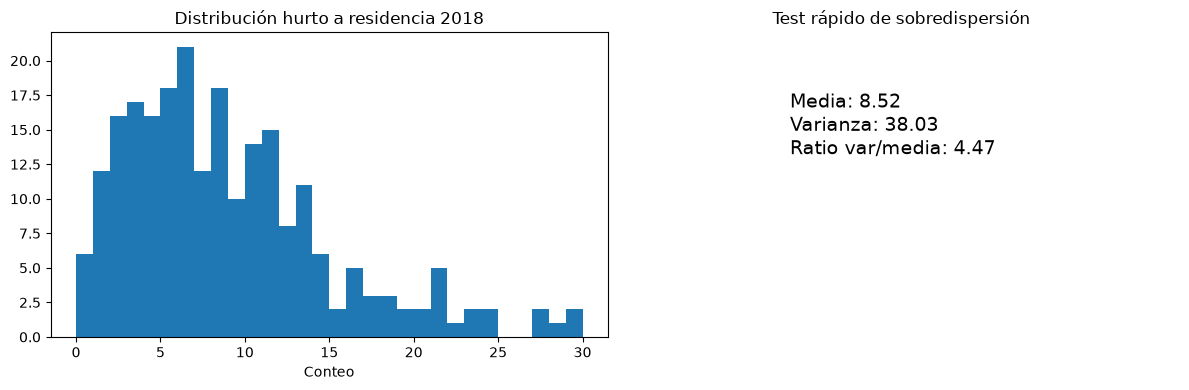

In [64]:
# --- Paso 3: Explorar variable respuesta ---
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histograma de conteos
axes[0].hist(df18["hurto_res"].dropna(), bins=30)
axes[0].set_title("Distribución hurto a residencia 2018")
axes[0].set_xlabel("Conteo")

# Media vs varianza (Poisson asume media = varianza)
media = df18["hurto_res"].mean()
varianza = df18["hurto_res"].var()
axes[1].text(0.3, 0.6, f"Media: {media:.2f}\nVarianza: {varianza:.2f}\nRatio var/media: {varianza/media:.2f}",
             transform=axes[1].transAxes, fontsize=14)
axes[1].set_title("Test rápido de sobredispersión")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [75]:
# --- Paso 4: GLM Poisson ---
import statsmodels.api as sm
import statsmodels.formula.api as smf

model_data = df18[["hurto_res", "log_tasa_hurto_per", "log_tasa_incaut_spa",
                    "viirs", "estrato_moda", "log_viv"]].dropna()

print(f"Observaciones en el modelo: {len(model_data)}")

poisson = smf.glm(
    formula="hurto_res ~ log_tasa_hurto_per + log_tasa_incaut_spa + viirs + estrato_moda",
    data=model_data,
    family=sm.families.Poisson(),
    offset=model_data["log_viv"]
).fit()

print(poisson.summary())

Observaciones en el modelo: 232
                 Generalized Linear Model Regression Results                  
Dep. Variable:              hurto_res   No. Observations:                  232
Model:                            GLM   Df Residuals:                      227
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -634.21
Date:                Sun, 25 Oct 2026   Deviance:                       415.72
Time:                        18:38:31   Pearson chi2:                     440.
No. Iterations:                     5   Pseudo R-squ. (CS):             0.8689
Covariance Type:            nonrobust                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
In

In [76]:
# --- Paso 5: Test de sobredispersión y Binomial Negativa ---

# Dispersión del Poisson: deviance / grados de libertad
disp = poisson.deviance / poisson.df_resid
print(f"Dispersión (deviance/df): {disp:.3f}")
print("Si >> 1, confirma sobredispersión\n")

# Binomial Negativa
nb = smf.glm(
    formula="hurto_res ~ log_tasa_hurto_per + log_tasa_incaut_spa + viirs + estrato_moda",
    data=model_data,
    family=sm.families.NegativeBinomial(),
    offset=model_data["log_viv"]
).fit()

print(nb.summary())

# Comparar AIC
print(f"\nAIC Poisson: {poisson.aic:.1f}")
print(f"AIC Binomial Negativa: {nb.aic:.1f}")

Dispersión (deviance/df): 1.831
Si >> 1, confirma sobredispersión

                 Generalized Linear Model Regression Results                  
Dep. Variable:              hurto_res   No. Observations:                  232
Model:                            GLM   Df Residuals:                      227
Model Family:        NegativeBinomial   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -707.80
Date:                Sun, 25 Oct 2026   Deviance:                       62.047
Time:                        18:38:43   Pearson chi2:                     57.5
No. Iterations:                     7   Pseudo R-squ. (CS):             0.1948
Covariance Type:            nonrobust                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------

c:\Users\usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\genmod\families\family.py:1367: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  warnings.warn("Negative binomial dispersion parameter alpha not "


In [78]:
# --- Paso 5b: Binomial Negativa con alpha estimado ---
import statsmodels.discrete.discrete_model as dm

model_data = model_data.copy()

nb2 = dm.NegativeBinomialP(
    endog=model_data["hurto_res"],
    exog=sm.add_constant(model_data[["log_tasa_hurto_per", "log_tasa_incaut_spa", "viirs", "estrato_moda"]]),
    offset=model_data["log_viv"],
    p=2
).fit()

print(nb2.summary())
print(f"\nAlpha estimado: {nb2.params.iloc[-1]:.4f}")
print(f"AIC Poisson: {poisson.aic:.1f}")
print(f"AIC NB: {nb2.aic:.1f}")

Optimization terminated successfully.
         Current function value: 2.633343
         Iterations: 13
         Function evaluations: 20
         Gradient evaluations: 20
                     NegativeBinomialP Regression Results                     
Dep. Variable:              hurto_res   No. Observations:                  232
Model:              NegativeBinomialP   Df Residuals:                      227
Method:                           MLE   Df Model:                            4
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                  0.1227
Time:                        18:39:48   Log-Likelihood:                -610.94
converged:                       True   LL-Null:                       -696.41
Covariance Type:            nonrobust   LLR p-value:                 6.571e-36
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               

In [79]:
# --- Paso 6: NB sin incautaciones ---
nb3 = dm.NegativeBinomialP(
    endog=model_data["hurto_res"],
    exog=sm.add_constant(model_data[["log_tasa_hurto_per", "viirs", "estrato_moda"]]),
    offset=model_data["log_viv"],
    p=2
).fit()

print(nb3.summary())
print(f"\nAIC con incautaciones: {nb2.aic:.1f}")
print(f"AIC sin incautaciones: {nb3.aic:.1f}")

Optimization terminated successfully.
         Current function value: 2.633366
         Iterations: 12
         Function evaluations: 19
         Gradient evaluations: 19
                     NegativeBinomialP Regression Results                     
Dep. Variable:              hurto_res   No. Observations:                  232
Model:              NegativeBinomialP   Df Residuals:                      228
Method:                           MLE   Df Model:                            3
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                  0.1227
Time:                        18:40:18   Log-Likelihood:                -610.94
converged:                       True   LL-Null:                       -696.41
Covariance Type:            nonrobust   LLR p-value:                 8.016e-37
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 

In [80]:
# --- Paso 7: Interpretación de coeficientes ---
import numpy as np

coefs = nb3.params[:-1]  # sin alpha
irr = np.exp(coefs)

print("Incidence Rate Ratios (IRR):")
for name, val in irr.items():
    print(f"  {name}: {val:.4f}")

Incidence Rate Ratios (IRR):
  const: 0.0004
  log_tasa_hurto_per: 1.0796
  viirs: 1.0153
  estrato_moda: 1.3335


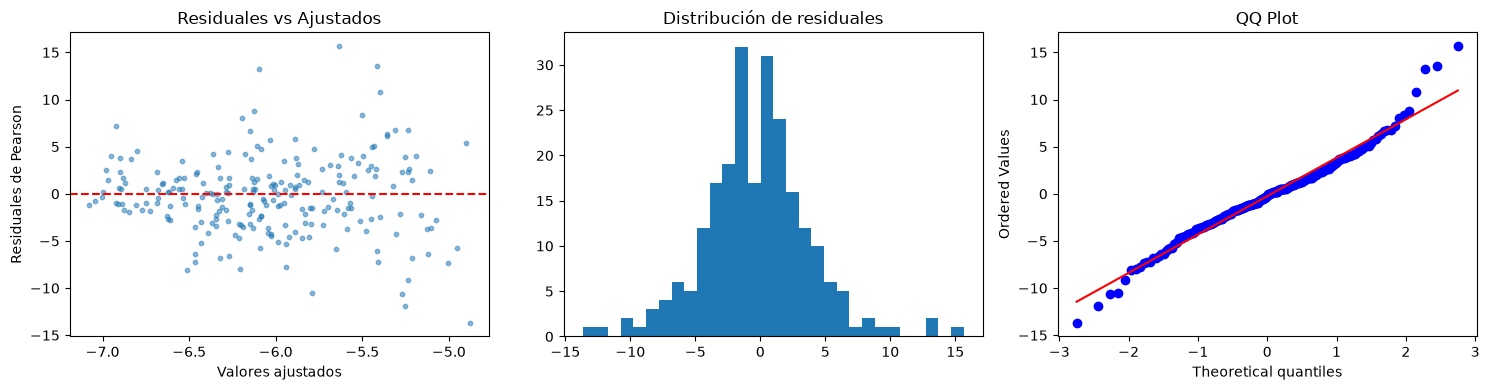

Media residuales: -0.2469
Desv. est. residuales: 4.0982


In [81]:
# --- Paso 8: Diagnóstico de residuales ---
import matplotlib.pyplot as plt

# Residuales de Pearson
model_data = model_data.copy()
model_data["fitted"] = nb3.fittedvalues
model_data["resid_pearson"] = nb3.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Residuales vs ajustados
axes[0].scatter(model_data["fitted"], model_data["resid_pearson"], alpha=0.5, s=10)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Valores ajustados")
axes[0].set_ylabel("Residuales de Pearson")
axes[0].set_title("Residuales vs Ajustados")

# Histograma de residuales
axes[1].hist(model_data["resid_pearson"], bins=30)
axes[1].set_title("Distribución de residuales")

# QQ plot
from scipy import stats
stats.probplot(model_data["resid_pearson"], plot=axes[2])
axes[2].set_title("QQ Plot")

plt.tight_layout()
plt.show()

print(f"Media residuales: {model_data['resid_pearson'].mean():.4f}")
print(f"Desv. est. residuales: {model_data['resid_pearson'].std():.4f}")

In [82]:
# --- Paso 9: Moran's I en residuales ---
from libpysal.weights import Queen
from esda.moran import Moran

# Necesitamos el GeoDataFrame con geometría
df18_model = df18.loc[model_data.index].copy()
df18_model["resid_pearson"] = model_data["resid_pearson"].values

# Matriz de pesos espaciales (contigüidad Queen)
w = Queen.from_dataframe(df18_model)
w.transform = "r"

# Moran's I
moran = Moran(df18_model["resid_pearson"], w)

print(f"Moran's I: {moran.I:.4f}")
print(f"Valor esperado: {moran.EI:.4f}")
print(f"p-value: {moran.p_sim:.4f}")

c:\Users\usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\usuario\AppData\Local\Temp\ipykernel_1444\1499696628.py:10: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(df18_model)


Moran's I: 0.0909
Valor esperado: -0.0043
p-value: 0.0110


In [83]:
# --- Paso 10: Tests LM para elegir SAR vs SEM ---
from spreg import OLS
from esda.moran import Moran_Local
import numpy as np

# Los tests LM clásicos funcionan sobre OLS, no sobre NB.
# Los corremos sobre la tasa como aproximación lineal
df18_model["tasa_hurto_res"] = (df18_model["hurto_res"] / df18_model["viviendas"]) * 1000

y = df18_model["tasa_hurto_res"].values.reshape(-1, 1)
X = df18_model[["log_tasa_hurto_per", "viirs", "estrato_moda"]].values

ols = OLS(y, X, w=w, spat_diag=True, name_y="tasa_hurto_res",
          name_x=["log_tasa_hurto_per", "viirs", "estrato_moda"])

print(ols.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :tasa_hurto_res                Number of Observations:         232
Mean dependent var  :      2.8010                Number of Variables   :           4
S.D. dependent var  :      2.0664                Degrees of Freedom    :         228
R-squared           :      0.4598
Adjusted R-squared  :      0.4527
Sum squared residual:      532.86                F-statistic           :     64.6821
Sigma-square        :       2.337                Prob(F-statistic)     :   2.687e-30
S.E. of regression  :       1.529                Log likelihood        :    -425.650
Sigma-square ML     :       2.297                Akaike info criterion :     859.301
S.E of regression ML:      1.5155                Schwarz criterion     :     873.088

---------------

c:\Users\usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


In [84]:
# --- Paso 11: Modelo SAR Lag ---
from spreg import ML_Lag

sar = ML_Lag(y, X, w=w, name_y="tasa_hurto_res",
             name_x=["log_tasa_hurto_per", "viirs", "estrato_moda"])

print(sar.summary)

ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :tasa_hurto_res                Number of Observations:         232
Mean dependent var  :      2.8010                Number of Variables   :           5
S.D. dependent var  :      2.0664                Degrees of Freedom    :         227
Pseudo R-squared    :      0.5299
Spatial Pseudo R-squared:  0.4950
Log likelihood      :   -413.7396
Sigma-square ML     :      2.0016                Akaike info criterion :     837.479
S.E of regression   :      1.4148                Schwarz criterion     :     854.713

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
-----------------------------------

In [ ]:
# --- Paso 12: Moran's I en residuales del SAR ---
moran_sar = Moran(sar.u.flatten(), w)
print(f"Moran's I residuales SAR: {moran_sar.I:.4f} (p={moran_sar.p_sim:.4f})")

print("=== Comparación de modelos ===")
print(f"OLS  - AIC: {ols.aic:.1f}  R2: {ols.r2:.4f}")
print(f"SAR  - AIC: {sar.aic:.1f}  R2: {sar.pr2:.4f}")
print(f"\nCoeficiente espacial (rho): {sar.rho:.4f}")
print(f"\nMoran's I residuales OLS: {moran.I:.4f} (p={moran.p_sim:.4f})")
print(f"Moran's I residuales SAR: {moran_sar.I:.4f} (p={moran_sar.p_sim:.4f})")

=== Comparación de modelos ===
OLS  - AIC: 859.3  R2: 0.4598
SAR  - AIC: 837.5  R2: 0.5299

Coeficiente espacial (rho): 0.4069

Moran's I residuales OLS: 0.0909 (p=0.0110)
Moran's I residuales SAR: 0.1365 (p=0.0010)


In [86]:
# --- Paso 13: SEM y comparación ---
from spreg import ML_Error

sem = ML_Error(y, X, w=w, name_y="tasa_hurto_res",
               name_x=["log_tasa_hurto_per", "viirs", "estrato_moda"])

moran_sem = Moran(sem.e_filtered, w)

print("=== Comparación completa ===")
print(f"OLS  - AIC: {ols.aic:.1f}")
print(f"SAR  - AIC: {sar.aic:.1f}  rho: {sar.rho:.4f}")
print(f"SEM  - AIC: {sem.aic:.1f}  lambda: {sem.lam:.4f}")
print(f"\nMoran's I residuales:")
print(f"  OLS: {moran.I:.4f} (p={moran.p_sim:.4f})")
print(f"  SAR: {moran_sar.I:.4f} (p={moran_sar.p_sim:.4f})")
print(f"  SEM: {moran_sem.I:.4f} (p={moran_sem.p_sim:.4f})")

c:\Users\usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
=== Comparación completa ===
OLS  - AIC: 859.3
SAR  - AIC: 837.5  rho: 0.4069
SEM  - AIC: 847.5  lambda: 0.3598

Moran's I residuales:
  OLS: 0.0909 (p=0.0110)
  SAR: 0.1365 (p=0.0010)
  SEM: -0.0096 (p=0.4610)


In [87]:
# --- Paso 14: Resumen del SEM ---
print(sem.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :tasa_hurto_res                Number of Observations:         232
Mean dependent var  :      2.8010                Number of Variables   :           4
S.D. dependent var  :      2.0664                Degrees of Freedom    :         228
Pseudo R-squared    :      0.4580
Log likelihood      :   -419.7648
Sigma-square ML     :      2.1256                Akaike info criterion :     847.530
S.E of regression   :      1.4579                Schwarz criterion     :     861.316

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
     

In [88]:
# --- Paso 14: GWR ---
from mgwr.gwr import GWR
from mgwr.sel_bw import Sel_BW
import numpy as np

# Coordenadas de centroides
coords = np.array([(g.centroid.x, g.centroid.y) for g in df18_model.geometry])

y_gwr = df18_model["tasa_hurto_res"].values.reshape(-1, 1)
X_gwr = df18_model[["log_tasa_hurto_per", "viirs", "estrato_moda"]].values

# Selección de ancho de banda
bw_selector = Sel_BW(coords, y_gwr, X_gwr)
bw = bw_selector.search()
print(f"Ancho de banda óptimo: {bw}")

# Ajustar GWR
gwr_model = GWR(coords, y_gwr, X_gwr, bw=bw).fit()

print(f"\nR2 GWR: {gwr_model.R2:.4f}")
print(f"AIC GWR: {gwr_model.aicc:.1f}")
print(f"AIC OLS: {ols.aic:.1f}")
print(f"AIC SEM: {sem.aic:.1f}")

Ancho de banda óptimo: 102.0

R2 GWR: 0.6122
AIC GWR: 821.1
AIC OLS: 859.3
AIC SEM: 847.5


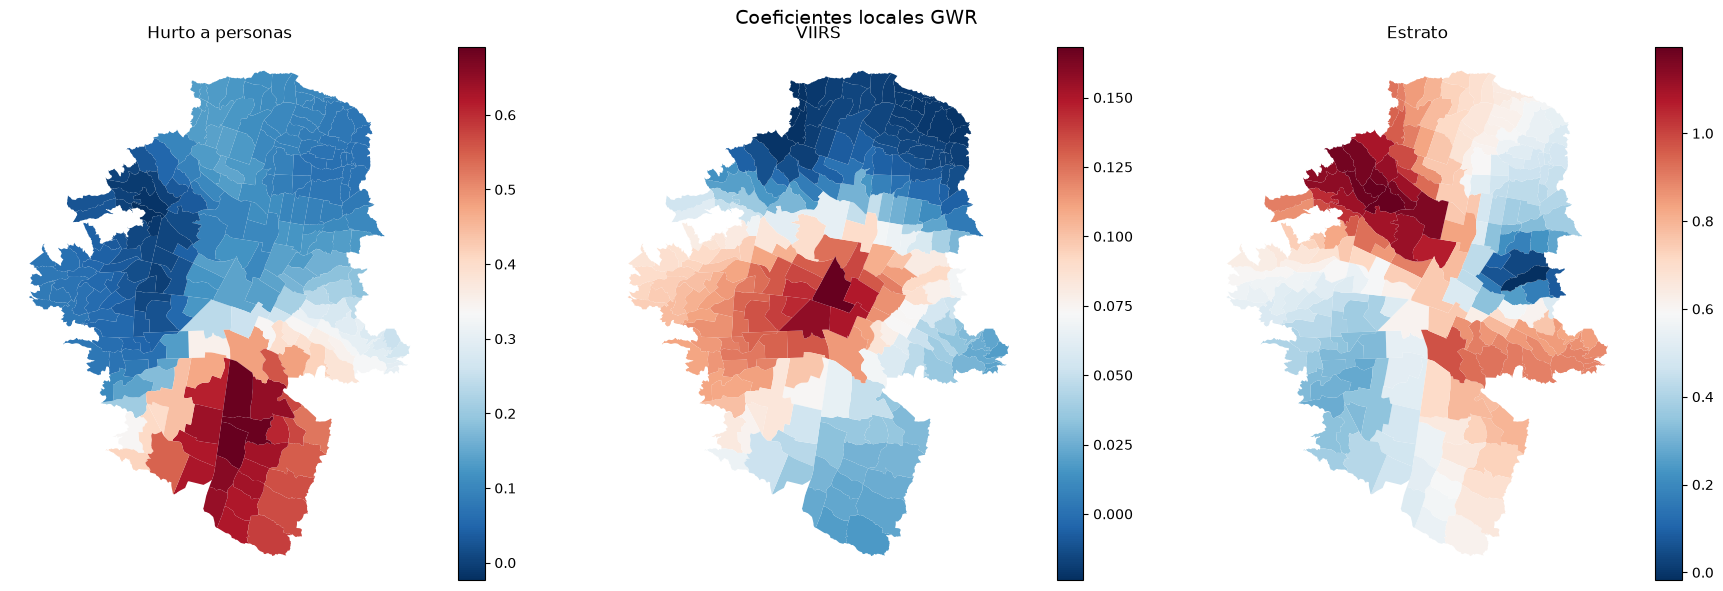

In [89]:
# --- Paso 15: Mapas de coeficientes locales ---
import matplotlib.pyplot as plt

df18_model = df18_model.copy()
df18_model["gwr_intercept"] = gwr_model.params[:, 0]
df18_model["gwr_hurto_per"] = gwr_model.params[:, 1]
df18_model["gwr_viirs"] = gwr_model.params[:, 2]
df18_model["gwr_estrato"] = gwr_model.params[:, 3]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

variables = [("gwr_hurto_per", "Hurto a personas"),
             ("gwr_viirs", "VIIRS"),
             ("gwr_estrato", "Estrato")]

for ax, (col, titulo) in zip(axes, variables):
    df18_model.plot(column=col, cmap="RdBu_r", legend=True, ax=ax)
    ax.set_title(titulo)
    ax.axis("off")

plt.suptitle("Coeficientes locales GWR", fontsize=14)
plt.tight_layout()
plt.show()

In [90]:
# --- Paso 16: MGWR ---
from mgwr.gwr import MGWR
from mgwr.sel_bw import Sel_BW

# Selección de anchos de banda (uno por variable)
bw_mgwr = Sel_BW(coords, y_gwr, X_gwr, multi=True)
bw_mgwr_vals = bw_mgwr.search()
print(f"Anchos de banda MGWR: {bw_mgwr_vals}")
print("  [intercepto, hurto_per, viirs, estrato]")

# Ajustar MGWR
mgwr_model = MGWR(coords, y_gwr, X_gwr, selector=bw_mgwr).fit()

print(f"\nR2 MGWR: {mgwr_model.R2:.4f}")
print(f"AIC MGWR: {mgwr_model.aicc:.1f}")
print(f"AIC GWR:  {gwr_model.aicc:.1f}")
print(f"AIC SEM:  {sem.aic:.1f}")
print(f"AIC OLS:  {ols.aic:.1f}")

Backfitting:  64%|██████▍   | 128/200 [01:59<01:07,  1.07it/s]


Anchos de banda MGWR: [230.  44. 115. 230.]
  [intercepto, hurto_per, viirs, estrato]


c:\Users\usuario\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mgwr\gwr.py:1603: RuntimeWarning: invalid value encountered in divide
  CCT[:, j] += ((pR[:, :, j] / self.X[:, j].reshape(-1, 1))**2).sum(
Inference: 100%|██████████| 1/1 [00:00<00:00, 14979.66it/s]


R2 MGWR: 0.5913
AIC MGWR: 828.7
AIC GWR:  821.1
AIC SEM:  847.5
AIC OLS:  859.3


In [92]:
print("Anchos de banda MGWR:")
print(f"  Intercepto:  {bw_mgwr_vals[0]}")
print(f"  Hurto pers:  {bw_mgwr_vals[1]}")
print(f"  VIIRS:       {bw_mgwr_vals[2]}")
print(f"  Estrato:     {bw_mgwr_vals[3]}")
print(f"\nN observaciones: {len(df18_model)}")

Anchos de banda MGWR:
  Intercepto:  230.0
  Hurto pers:  44.0
  VIIRS:       115.0
  Estrato:     230.0

N observaciones: 232


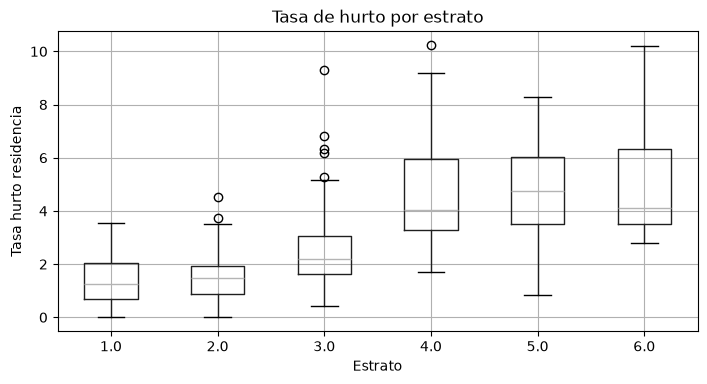

In [91]:
# --- Relación estrato vs tasa de hurto ---
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
df18_model.boxplot(column="tasa_hurto_res", by="estrato_moda", ax=ax)
ax.set_xlabel("Estrato")
ax.set_ylabel("Tasa hurto residencia")
plt.suptitle("")
ax.set_title("Tasa de hurto por estrato")
plt.show()

In [94]:
# --- Moran's I residuales GWR y MGWR ---
moran_gwr = Moran(gwr_model.resid_response.flatten(), w)
moran_mgwr = Moran(mgwr_model.resid_response.flatten(), w)

print(f"Moran's I residuales GWR:  {moran_gwr.I:.4f} (p={moran_gwr.p_sim:.4f})")
print(f"Moran's I residuales MGWR: {moran_mgwr.I:.4f} (p={moran_mgwr.p_sim:.4f})")

Moran's I residuales GWR:  -0.0275 (p=0.2920)
Moran's I residuales MGWR: 0.0058 (p=0.3950)


In [96]:
print("=== Resumen comparativo ===")
print(f"{'Modelo':<10} {'AIC':>8} {'R2':>8} {'Moran I resid':>15}")
print(f"{'OLS':<10} {ols.aic:>8.1f} {ols.r2:>8.4f} {moran.I:>12.4f} (p={moran.p_sim:.3f})")
print(f"{'SEM':<10} {sem.aic:>8.1f} {'':>8} {moran_sem.I:>12.4f} (p={moran_sem.p_sim:.3f})")
print(f"{'SAR':<10} {sar.aic:>8.1f} {sar.pr2:>8.4f} {moran_sar.I:>12.4f} (p={moran_sar.p_sim:.3f})")
print(f"{'GWR':<10} {gwr_model.aicc:>8.1f} {gwr_model.R2:>8.4f} {moran_gwr.I:>12.4f} (p={moran_gwr.p_sim:.3f})")
print(f"{'MGWR':<10} {mgwr_model.aicc:>8.1f} {mgwr_model.R2:>8.4f} {moran_mgwr.I:>12.4f} (p={moran_mgwr.p_sim:.3f})")
print(f"\n{'NB (conteo)':<10} AIC: {nb3.aic:.1f}")

=== Resumen comparativo ===
Modelo          AIC       R2   Moran I resid
OLS           859.3   0.4598       0.0909 (p=0.011)
SEM           847.5               -0.0096 (p=0.461)
SAR           837.5   0.5299       0.1365 (p=0.001)
GWR           821.1   0.6122      -0.0275 (p=0.292)
MGWR          828.7   0.5913       0.0058 (p=0.395)

NB (conteo) AIC: 1231.9


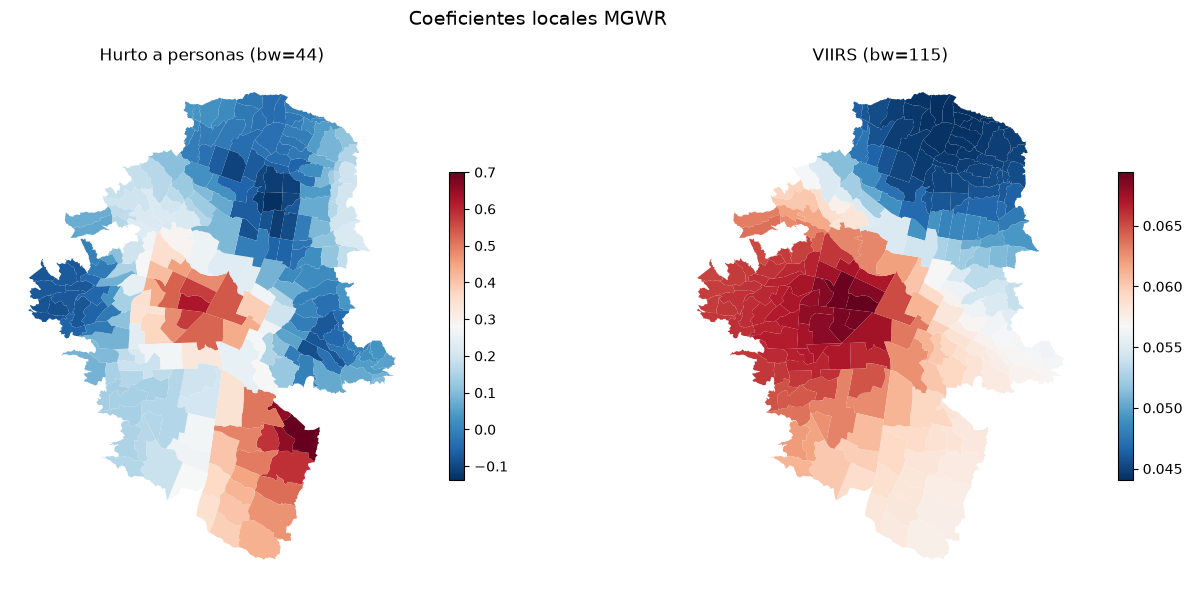

In [97]:
# --- Paso 18: Mapas MGWR ---
import matplotlib.pyplot as plt

df18_model["mgwr_intercept"] = mgwr_model.params[:, 0]
df18_model["mgwr_hurto_per"] = mgwr_model.params[:, 1]
df18_model["mgwr_viirs"] = mgwr_model.params[:, 2]
df18_model["mgwr_estrato"] = mgwr_model.params[:, 3]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

variables = [("mgwr_hurto_per", "Hurto a personas (bw=44)"),
             ("mgwr_viirs", "VIIRS (bw=115)")]

for ax, (col, titulo) in zip(axes, variables):
    df18_model.plot(column=col, cmap="RdBu_r", legend=True, ax=ax,
                    legend_kwds={"shrink": 0.6})
    ax.set_title(titulo)
    ax.axis("off")

plt.suptitle("Coeficientes locales MGWR", fontsize=14)
plt.tight_layout()
plt.show()

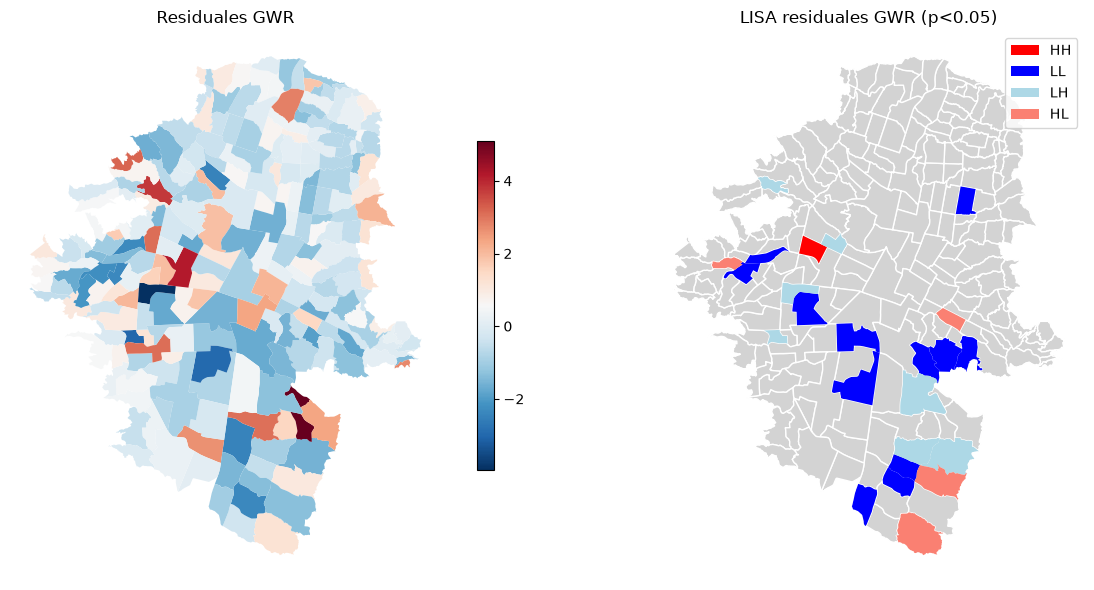

In [98]:
# --- Paso 19: Mapa de residuales y LISA ---
from esda.moran import Moran_Local

# Residuales del mejor modelo (GWR por AIC)
df18_model["resid_gwr"] = gwr_model.resid_response.flatten()

# LISA
lisa = Moran_Local(df18_model["resid_gwr"], w)
df18_model["lisa_q"] = lisa.q
df18_model["lisa_sig"] = lisa.p_sim < 0.05

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Mapa de residuales
df18_model.plot(column="resid_gwr", cmap="RdBu_r", legend=True, ax=axes[0],
                legend_kwds={"shrink": 0.6})
axes[0].set_title("Residuales GWR")
axes[0].axis("off")

# LISA significativo
labels = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
df18_model["lisa_label"] = df18_model["lisa_q"].map(labels)
sig = df18_model[df18_model["lisa_sig"]]

df18_model.plot(color="lightgrey", edgecolor="white", ax=axes[1])
if len(sig) > 0:
    colors = {"HH": "red", "LL": "blue", "LH": "lightblue", "HL": "salmon"}
    for label, color in colors.items():
        subset = sig[sig["lisa_label"] == label]
        if len(subset) > 0:
            subset.plot(color=color, ax=axes[1], label=label)
    axes[1].legend()
axes[1].set_title("LISA residuales GWR (p<0.05)")
axes[1].axis("off")

plt.tight_layout()
plt.show()